# Grupo 1 — Sentilytics

## APF1 corregido: baseline TF-IDF + Regresión Logística balanced

Objetivos:

1. Mantener un baseline TF-IDF reproducible.
2. Evitar fuga de información.
3. Evaluar especialmente las reseñas negativas (clase 0, clase de interés operativo).
4. Guardar los mismos textos e IDs para APF2 y el fine-tuning.
5. Reservar el test interno para la comparación final de los tres pipelines.
6. Documentar los cambios respecto a la versión revisada por el docente.

## Cambios respecto a la versión revisada por el docente

La revisión docente del 5/10/2026 se realizó sobre
`Grupo1_APF1(20261005-170953).ipynb`. Las particiones son las mismas
(misma semilla 42, misma estratificación 70/15/15 y mismas posiciones en
validación); cambian la limpieza, el vectorizador y la regla de decisión.

| Elemento | Versión revisada | Versión actual | Motivo |
|---|---|---|---|
| Puntuación | Se elimina toda (`[^\w\s]`) | Se conservan `!` y `?`; se elimina el resto | Los signos de exclamación e interrogación aportan intensidad y tono |
| Números | Se eliminan (`\d+`) | Se conservan | Expresiones como "5 estrellas" o "2 horas de espera" aportan contexto |
| Enlaces y usuarios | Sin tratamiento | Se reemplazan por `url` y `usuario` | Evitar vocabulario irrepetible |
| Stopwords | Lista NLTK en español excluyendo `no`, `nunca`, `sin` | `stop_words=None` (no se elimina ninguna) | La lista NLTK también elimina palabras con carga de polaridad (por ejemplo `muy`, `nada`, `pero`, `ni`) |
| `min_df` / `max_df` | Por defecto (1 / 1.0) | 2 / 0.95 | Descartar términos que aparecen una sola vez y términos casi universales |
| `sublinear_tf` | `False` | `True` | Atenuar el peso de palabras repetidas dentro de una reseña |
| Dimensión TF-IDF | 720 × 5000 (el informe decía por error 1 029 × 5 000) | 720 × 1765 | Con `min_df=2` el vocabulario real no alcanza el límite de 5000 |
| Pesos de clase | Se comparó sin ponderar vs `balanced`; se eligió `balanced` (F1 negativo 0.07 vs 0.62) | Se mantiene `balanced` | Decisión ya tomada con validación |
| Regla de decisión | `predict()`: umbral fijo 0.50 sobre P(positiva) | P(negativa) vía `classes_` con umbral elegido en validación | Criterio de negocio común a los tres pipelines |
| Análisis de errores | Mensaje "errores en test" sobre datos de validación | Etiquetado como validación | Corrección de coherencia |

Todas las decisiones se tomaron con validación; el test interno no se
utilizó. Como limpieza, vectorizador y umbral se ajustaron mirando
validación, las métricas de validación pueden ser algo optimistas: por
eso la comparación final se hace en test y en el test oficial
independiente.

La comparación de métricas entre ambas versiones se imprime
automáticamente después de la evaluación en validación.

In [1]:
!pip -q install datasets joblib

In [2]:
import re
import json
import joblib
import sklearn
import datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

SEMILLA = 42
np.random.seed(SEMILLA)

print("Semilla:", SEMILLA)

Semilla: 42


In [3]:
dataset = load_dataset(
    "mteb/SpanishSentimentClassification",
    split="train"
)

df = dataset.to_pandas()[["text", "label"]].copy()

df = df.rename(columns={
    "text": "texto",
    "label": "sentimiento"
})

print("Cantidad inicial:", len(df))
display(df.head())

README.md:   0%|          | 0.00/6.34k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 59.6kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 10.7kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/1029 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/147 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/296 [00:00<?, ? examples/s]

Cantidad inicial: 1029


,texto,sentimiento
0,"Está situado en el centro de la ciudad , con t...",1
1,"un lugar hermosisimo , inolvidable. hermosa at...",1
2,Todo absolutamente recomendable .,1
3,El metro está a 50 metros bajando tan solo una...,1
4,Y de Toscana ... mejor que lo veais ... y adem...,1


## Control de calidad

Antes de dividir los datos se revisan textos repetidos y posibles
contradicciones de etiquetado.

In [4]:
df["texto"] = df["texto"].astype(str).str.strip()

# Eliminar textos vacíos
df = df[df["texto"] != ""].copy()

# Buscar textos iguales con etiquetas diferentes
conflictos = (
    df.groupby("texto")["sentimiento"]
      .nunique()
)

textos_conflictivos = conflictos[conflictos > 1]

print("Textos con etiquetas contradictorias:",
      len(textos_conflictivos))

# Detener el proceso si existen contradicciones
assert len(textos_conflictivos) == 0, (
    "Existen textos iguales con etiquetas diferentes. "
    "Deben revisarse manualmente."
)

# Eliminar duplicados exactos
df = (
    df.drop_duplicates(subset=["texto", "sentimiento"])
      .reset_index(drop=True)
)

# ID estable para cada reseña
df["review_id"] = np.arange(len(df))

print("Cantidad final:", len(df))
print("\nDistribución:")
print(df["sentimiento"].value_counts())

Textos con etiquetas contradictorias: 0
Cantidad final: 1029

Distribución:
sentimiento
1    851
0    178
Name: count, dtype: int64


## Rutas de procesamiento

- **TF-IDF** utiliza `texto_tfidf`: minúsculas, sin enlaces ni usuarios,
  conserva letras, números, `!` y `?`, y elimina el resto de signos.
- **Transformers (Sentence-BERT y BETO)** utilizan `texto_contextual`:
  el texto original con puntuación y mayúsculas (solo se quitan espacios
  al inicio y al final).
- No se eliminan stopwords (`stop_words=None`). En particular se
  conservan las negaciones `no`, `nunca` y `sin`, que invierten la
  polaridad.
- Eliminar puntuación puede perder matices (por ejemplo, `...` o comas
  que separan ideas contrapuestas). Por eso los Transformers reciben el
  texto original.

In [5]:
def limpiar_texto(texto):
    texto = str(texto).lower().strip()

    # Reemplazar enlaces y usuarios (en minúsculas para que la
    # regex siguiente no los elimine)
    texto = re.sub(r"http\S+|www\.\S+", " url ", texto)
    texto = re.sub(r"@\w+", " usuario ", texto)

    # Mantener letras, números, ! y ?
    texto = re.sub(
        r"[^a-záéíóúüñ0-9!? ]+",
        " ",
        texto
    )

    # Compactar espacios
    texto = re.sub(r"\s+", " ", texto)

    return texto.strip()


df["texto_tfidf"] = df["texto"].apply(limpiar_texto)

df["texto_contextual"] = (
    df["texto"]
      .astype(str)
      .str.strip()
)

display(
    df[
        ["review_id", "texto", "texto_tfidf",
         "texto_contextual", "sentimiento"]
    ].head()
)

,review_id,texto,texto_tfidf,texto_contextual,sentimiento
0,0,"Está situado en el centro de la ciudad , con t...",está situado en el centro de la ciudad con tod...,"Está situado en el centro de la ciudad , con t...",1
1,1,"un lugar hermosisimo , inolvidable. hermosa at...",un lugar hermosisimo inolvidable hermosa atenc...,"un lugar hermosisimo , inolvidable. hermosa at...",1
2,2,Todo absolutamente recomendable .,todo absolutamente recomendable,Todo absolutamente recomendable .,1
3,3,El metro está a 50 metros bajando tan solo una...,el metro está a 50 metros bajando tan solo una...,El metro está a 50 metros bajando tan solo una...,1
4,4,Y de Toscana ... mejor que lo veais ... y adem...,y de toscana mejor que lo veais y además delo ...,Y de Toscana ... mejor que lo veais ... y adem...,1


## Auditoría de duplicados después de la limpieza

La limpieza puede volver idénticos textos que en crudo eran distintos
(por ejemplo, `Excelente` y `Excelente .`). Se revisa:

1. Si aparecen etiquetas contradictorias tras la limpieza.
2. Cuántas reseñas quedan duplicadas.

Decisión: los duplicados tras limpieza **no se eliminan**, para no
alterar las particiones ya utilizadas por APF2. Su solapamiento entre
particiones se reporta después de la división y su efecto se mide en la
evaluación final (métricas con y sin esas reseñas).

In [6]:
grupos_limpios = df.groupby("texto_tfidf")["sentimiento"].nunique()
conflictos_limpios = grupos_limpios[grupos_limpios > 1]

duplicados_limpios = (
    df[df.duplicated("texto_tfidf", keep=False)]
      .sort_values("texto_tfidf")
)

print("Textos limpios con etiquetas contradictorias:",
      len(conflictos_limpios))
print("Reseñas duplicadas tras la limpieza:",
      len(duplicados_limpios),
      "en", duplicados_limpios["texto_tfidf"].nunique(), "grupos")

assert len(conflictos_limpios) == 0, (
    "La limpieza generó textos iguales con etiquetas diferentes."
)

display(
    duplicados_limpios[
        ["review_id", "texto", "texto_tfidf", "sentimiento"]
    ]
)

Textos limpios con etiquetas contradictorias: 0
Reseñas duplicadas tras la limpieza: 12 en 6 grupos


,review_id,texto,texto_tfidf,sentimiento
82,82,Buena relación calidad precio,buena relación calidad precio,1
636,636,Buena relación calidad · precio,buena relación calidad precio,1
755,755,Excelente .,excelente,1
802,802,Excelente,excelente,1
318,318,Genial .,genial,1
683,683,Genial,genial,1
878,878,Muy céntrico .,muy céntrico,1
977,977,Muy céntrico,muy céntrico,1
540,540,Muy recomendable .,muy recomendable,1
645,645,Muy recomendable,muy recomendable,1


## División de datos

Se utiliza una división estratificada para mantener aproximadamente
la misma proporción de reseñas positivas y negativas.

Los IDs se guardan para que TF-IDF y Sentence-BERT utilicen
exactamente los mismos ejemplos.

In [7]:
indices = np.arange(len(df))
y = df["sentimiento"].to_numpy()

# 70 % entrenamiento y 30 % temporal
idx_train, idx_temporal = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEMILLA,
    stratify=y
)

# 15 % validación y 15 % test
idx_val, idx_test = train_test_split(
    idx_temporal,
    test_size=0.50,
    random_state=SEMILLA,
    stratify=y[idx_temporal]
)

df_train = df.iloc[idx_train].copy()
df_val   = df.iloc[idx_val].copy()
df_test  = df.iloc[idx_test].copy()

print("Train:", len(df_train))
print("Validación:", len(df_val))
print("Test:", len(df_test))

Train: 720
Validación: 154
Test: 155


In [8]:
ids_train = set(df_train["review_id"])
ids_val   = set(df_val["review_id"])
ids_test  = set(df_test["review_id"])

assert ids_train.isdisjoint(ids_val)
assert ids_train.isdisjoint(ids_test)
assert ids_val.isdisjoint(ids_test)

print("Correcto: no existen IDs compartidos.")

# Solapamiento de texto limpio entre particiones
limpios_train = set(df_train["texto_tfidf"])
limpios_train_val = limpios_train | set(df_val["texto_tfidf"])

solapados_val = df_val[
    df_val["texto_tfidf"].isin(limpios_train)
]
solapados_test = df_test[
    df_test["texto_tfidf"].isin(limpios_train_val)
]

ids_solapados = {
    "validacion": solapados_val["review_id"].tolist(),
    "test": solapados_test["review_id"].tolist()
}

print("\nReseñas de validación cuyo texto limpio aparece en train:",
      len(solapados_val))
print("Reseñas de test cuyo texto limpio aparece en train/validación:",
      len(solapados_test))

display(pd.concat([solapados_val, solapados_test])[
    ["review_id", "texto", "texto_tfidf", "sentimiento"]
])

Correcto: no existen IDs compartidos.

Reseñas de validación cuyo texto limpio aparece en train: 0
Reseñas de test cuyo texto limpio aparece en train/validación: 2


,review_id,texto,texto_tfidf,sentimiento
977,977,Muy céntrico,muy céntrico,1
177,177,Recomendable .,recomendable,1


In [9]:
X_train = df_train["texto_tfidf"]
X_val   = df_val["texto_tfidf"]

y_train = df_train["sentimiento"]
y_val   = df_val["sentimiento"]

# Textos originales para analizar errores
X_val_text = df_val["texto"].reset_index(drop=True)

## TF-IDF sin fuga

El vectorizador aprende el vocabulario y los pesos IDF solamente
con entrenamiento (720 reseñas).

Validación únicamente aplica lo aprendido. El test interno no se
transforma ni se evalúa en este notebook.

`max_features=5000` es un límite superior, no la dimensión garantizada:
con `min_df=2` el vocabulario real es menor y se reporta a continuación.

In [10]:
vectorizador = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=5000,
    sublinear_tf=True,
    stop_words=None
)

X_train_tfidf = vectorizador.fit_transform(X_train)
X_val_tfidf = vectorizador.transform(X_val)

print("Train:", X_train_tfidf.shape)
print("Validación:", X_val_tfidf.shape)
print("Vocabulario real:", len(vectorizador.vocabulary_),
      "términos (límite max_features = 5000)")

Train: (720, 1765)
Validación: (154, 1765)
Vocabulario real: 1765 términos (límite max_features = 5000)


## Entrenamiento de la Regresión Logística

In [11]:
modelo = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=1000,
    random_state=SEMILLA
)

modelo.fit(X_train_tfidf, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


## Selección del umbral

El umbral se elige únicamente con validación. El test interno no
participa en esta decisión.

- Se usa la probabilidad de la clase **0 (negativa)**, localizada con
  `modelo.classes_`.
- Una reseña se envía a la cola de revisión si
  `P(negativa) >= umbral`.
- **Criterio de negocio, fijado antes de evaluar test:** maximizar el
  recall negativo (no dejar quejas sin atender) con una precisión
  negativa mínima de 0.60. Es decir, de cada 10 reseñas enviadas a
  revisión, al menos 6 deben ser quejas reales, para no saturar al
  equipo con falsas alarmas. Desempate por mayor F1 negativo y luego por
  el umbral más cercano a 0.50.
- Se descartó maximizar solo F1 negativo: en validación elegía un
  umbral que ganaba 0.004 de F1 a cambio de omitir 2 quejas más, una
  diferencia que con 26 negativas es ruido y va contra el objetivo de
  negocio.
- La misma rejilla y el mismo criterio se aplican en APF2 y en el
  fine-tuning.
- El umbral no reentrena el clasificador, y la probabilidad no equivale
  a la gravedad de la insatisfacción.

In [12]:
REJILLA_UMBRAL = np.round(np.arange(0.30, 0.701, 0.02), 2)

PRECISION_NEGATIVA_MINIMA = 0.60

CRITERIO_UMBRAL = (
    "Maximizar recall negativo en validación con precisión negativa "
    f">= {PRECISION_NEGATIVA_MINIMA:.2f} (tope de falsas alarmas); "
    "desempate por mayor F1 negativo y luego por el umbral más cercano "
    "a 0.50. Si ningún umbral cumple la restricción, se maximiza F1 "
    "negativo."
)


def seleccionar_umbral(y_real, prob_negativa, rejilla=REJILLA_UMBRAL):
    """Una reseña se marca como negativa (0) si prob_negativa >= umbral.
    Debe ser idéntica en los tres pipelines."""
    filas = []

    for umbral in rejilla:
        pred = np.where(prob_negativa >= umbral, 0, 1)

        filas.append({
            "umbral_negativo": float(umbral),
            "precision_negativa": precision_score(
                y_real, pred, pos_label=0, zero_division=0
            ),
            "recall_negativo": recall_score(
                y_real, pred, pos_label=0, zero_division=0
            ),
            "f1_negativo": f1_score(
                y_real, pred, pos_label=0, zero_division=0
            ),
            "f1_macro": f1_score(
                y_real, pred, average="macro", zero_division=0
            ),
            "alertas_generadas": int((pred == 0).sum())
        })

    tabla = pd.DataFrame(filas)
    tabla["cumple_precision"] = (
        tabla["precision_negativa"] >= PRECISION_NEGATIVA_MINIMA
    )
    tabla["distancia_050"] = (tabla["umbral_negativo"] - 0.50).abs()

    candidatos = tabla[tabla["cumple_precision"]]

    if candidatos.empty:
        mejor = tabla.sort_values(
            ["f1_negativo", "distancia_050"],
            ascending=[False, True]
        ).iloc[0]
    else:
        mejor = candidatos.sort_values(
            ["recall_negativo", "f1_negativo", "distancia_050"],
            ascending=[False, False, True]
        ).iloc[0]

    return (
        float(mejor["umbral_negativo"]),
        tabla.drop(columns="distancia_050")
    )


idx_negativa = list(modelo.classes_).index(0)

prob_val_negativa = modelo.predict_proba(
    X_val_tfidf
)[:, idx_negativa]

UMBRAL_NEGATIVO, tabla_umbrales = seleccionar_umbral(
    y_val, prob_val_negativa
)

display(tabla_umbrales.round(4))
print("Umbral elegido con validación (P(negativa) >=):", UMBRAL_NEGATIVO)

,umbral_negativo,precision_negativa,recall_negativo,f1_negativo,f1_macro,alertas_generadas,cumple_precision
0,0.30,0.2524,1.0000,0.4031,0.4865,103,False
1,0.32,0.2796,1.0000,0.4370,0.5412,93,False
2,0.34,0.2921,1.0000,0.4522,0.5629,89,False
3,0.36,0.3095,1.0000,0.4727,0.5899,84,False
4,0.38,0.3289,0.9615,0.4902,0.6189,76,False
5,0.40,0.3676,0.9615,0.5319,0.6632,68,False
6,0.42,0.4510,0.8846,0.5974,0.7316,51,False
7,0.44,0.5116,0.8462,0.6377,0.7665,43,False
8,0.46,0.5556,0.7692,0.6452,0.7779,36,False
9,0.48,0.6250,0.7692,0.6897,0.8088,32,True


Umbral elegido con validación (P(negativa) >=): 0.48


In [13]:
def calcular_metricas(y_real, y_predicho):
    # labels=[1, 0]: la clase a detectar es la negativa (0)
    vn, fp, fn, vp = confusion_matrix(
        y_real, y_predicho, labels=[1, 0]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_real, y_predicho),
        "balanced_accuracy": balanced_accuracy_score(
            y_real, y_predicho
        ),
        "precision_negativa": precision_score(
            y_real, y_predicho, pos_label=0, zero_division=0
        ),
        "recall_negativo": recall_score(
            y_real, y_predicho, pos_label=0, zero_division=0
        ),
        "f1_negativo": f1_score(
            y_real, y_predicho, pos_label=0, zero_division=0
        ),
        "f1_macro": f1_score(
            y_real, y_predicho, average="macro", zero_division=0
        ),
        "quejas_detectadas_VP": int(vp),
        "quejas_omitidas_FN": int(fn),
        "falsas_alarmas_FP": int(fp),
        "positivas_correctas_VN": int(vn),
        "soporte_negativo": int(vp + fn)
    }


y_val_pred = np.where(
    prob_val_negativa >= UMBRAL_NEGATIVO, 0, 1
)

metricas_val = calcular_metricas(y_val, y_val_pred)

print("RESULTADOS DE VALIDACIÓN (no test)")
print("----------------------------------")
print(f"Accuracy:           {metricas_val['accuracy']:.4f}")
print(f"Balanced accuracy:  {metricas_val['balanced_accuracy']:.4f}")
print(f"F1 macro:           {metricas_val['f1_macro']:.4f}")
print(f"Precisión negativa: {metricas_val['precision_negativa']:.4f}")
print(f"Recall negativo:    {metricas_val['recall_negativo']:.4f}")
print(f"F1 negativo:        {metricas_val['f1_negativo']:.4f}")

print("\nConteos respecto a la detección de negativas:")
print(f"Quejas detectadas (VP): {metricas_val['quejas_detectadas_VP']}"
      f" de {metricas_val['soporte_negativo']}")
print(f"Quejas omitidas (FN):   {metricas_val['quejas_omitidas_FN']}")
print(f"Falsas alarmas (FP):    {metricas_val['falsas_alarmas_FP']}"
      f" de {int((y_val == 1).sum())} positivas")

print("\nReporte completo (validación):")
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Negativa", "Positiva"],
        zero_division=0
    )
)

RESULTADOS DE VALIDACIÓN (no test)
----------------------------------
Accuracy:           0.8831
Balanced accuracy:  0.8377
F1 macro:           0.8088
Precisión negativa: 0.6250
Recall negativo:    0.7692
F1 negativo:        0.6897

Conteos respecto a la detección de negativas:
Quejas detectadas (VP): 20 de 26
Quejas omitidas (FN):   6
Falsas alarmas (FP):    12 de 128 positivas

Reporte completo (validación):
              precision    recall  f1-score   support

    Negativa       0.62      0.77      0.69        26
    Positiva       0.95      0.91      0.93       128

    accuracy                           0.88       154
   macro avg       0.79      0.84      0.81       154
weighted avg       0.90      0.88      0.89       154



### Comparación con la versión revisada (validación)

Valores de la versión revisada tomados de su matriz de confusión
(14 VP, 12 FN, 5 FP, 123 VN).

In [14]:
version_revisada = {
    "accuracy": 137 / 154,
    "balanced_accuracy": (14 / 26 + 123 / 128) / 2,
    "precision_negativa": 14 / 19,
    "recall_negativo": 14 / 26,
    "f1_negativo": 28 / 45,
    "f1_macro": (28 / 45 + 246 / 263) / 2,
    "quejas_detectadas_VP": 14,
    "quejas_omitidas_FN": 12,
    "falsas_alarmas_FP": 5
}

comparacion_versiones = pd.DataFrame({
    "Versión revisada": version_revisada,
    "Versión actual": {k: metricas_val[k] for k in version_revisada}
})

display(comparacion_versiones.round(4))

,Versión revisada,Versión actual
accuracy,0.8896,0.8831
balanced_accuracy,0.7497,0.8377
precision_negativa,0.7368,0.6250
recall_negativo,0.5385,0.7692
f1_negativo,0.6222,0.6897
f1_macro,0.7788,0.8088
quejas_detectadas_VP,14.0000,20.0000
quejas_omitidas_FN,12.0000,6.0000
falsas_alarmas_FP,5.0000,12.0000


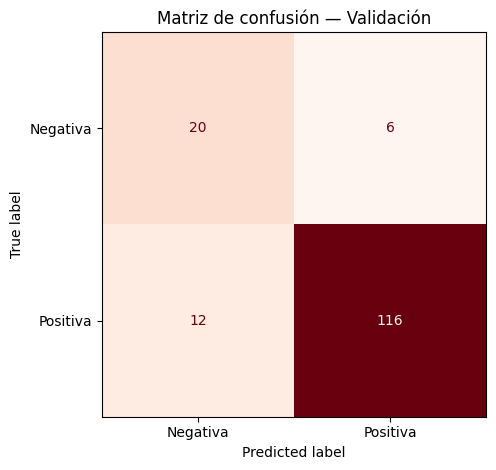

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=["Negativa", "Positiva"],
    cmap="Reds",
    colorbar=False
)

plt.title("Matriz de confusión — Validación")
plt.tight_layout()
plt.show()

In [16]:
y_val_array = y_val.to_numpy()

indices_error = np.where(
    y_val_array != y_val_pred
)[0]

df_errores = pd.DataFrame({
    "review_id": (
        df_val["review_id"]
        .reset_index(drop=True)
        .iloc[indices_error]
    ),
    "texto": X_val_text.iloc[indices_error],
    "real": y_val_array[indices_error],
    "predicho": y_val_pred[indices_error]
})

df_errores["tipo_error"] = np.where(
    df_errores["real"] == 0,
    "FN: queja omitida",
    "FP: falsa alarma"
)

print(
    "Total de errores en validación:",
    len(df_errores)
)
print(df_errores["tipo_error"].value_counts())

display(df_errores)

Total de errores en validación: 18
tipo_error
FP: falsa alarma     12
FN: queja omitida     6
Name: count, dtype: int64


,review_id,texto,real,predicho,tipo_error
5,911,Estancia decepcionante,0,1,FN: queja omitida
28,306,Inútil reclamar .,0,1,FN: queja omitida
33,465,Tiene unos precios bastante mas baratos en su ...,1,0,FP: falsa alarma
41,923,Personalmente adoro las alhomadas duspués de u...,1,0,FP: falsa alarma
43,564,"Las habitaciones son amplias , tienen una TV d...",1,0,FP: falsa alarma
44,319,"Bueno el hotel no era malo , estaba limpio y bien",1,0,FP: falsa alarma
59,871,"Regular , podría mejorar .",0,1,FN: queja omitida
71,863,La atencion un desastre,0,1,FN: queja omitida
75,40,El desayuno el resto de los días genial el buf...,1,0,FP: falsa alarma
81,432,"como la vez anterior , no nos defraudó en nada .",1,0,FP: falsa alarma


## Reproducibilidad

Se guardan el modelo, el vectorizador, el umbral y los mismos
identificadores que se utilizarán en APF2.

In [18]:
# ============================================================
# GUARDAR EL BASELINE APF1 EN GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

RUTA = Path(
    "/content/drive/MyDrive/Sentilytics/APF1"
)

RUTA.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    vectorizador,
    RUTA / "vectorizador_tfidf.joblib"
)

joblib.dump(
    modelo,
    RUTA / "regresion_logistica.joblib"
)

df_train.to_csv(RUTA / "train.csv", index=False)
df_val.to_csv(RUTA / "validacion.csv", index=False)
df_test.to_csv(RUTA / "test_reservado.csv", index=False)

pd.DataFrame({
    "review_id": df_val["review_id"].to_numpy(),
    "sentimiento": y_val_array,
    "prob_negativa": prob_val_negativa,
    "prediccion": y_val_pred
}).to_csv(RUTA / "probabilidades_validacion.csv", index=False)

configuracion = {
    "semilla": SEMILLA,
    "umbral_negativo": UMBRAL_NEGATIVO,
    "regla_decision": "negativa (0) si P(negativa) >= umbral_negativo",
    "criterio_umbral": CRITERIO_UMBRAL,
    "rejilla_umbral": REJILLA_UMBRAL.tolist(),

    "cantidad_datos": {
        "n_train": len(df_train),
        "n_validacion": len(df_val),
        "n_test": len(df_test)
    },

    "negativas_por_particion": {
        "train": int((df_train["sentimiento"] == 0).sum()),
        "validacion": int((df_val["sentimiento"] == 0).sum()),
        "test": int((df_test["sentimiento"] == 0).sum())
    },

    "vectorizador": {
        "tipo": "TF-IDF",
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_df": 0.95,
        "max_features": 5000,
        "n_features_reales": int(X_train_tfidf.shape[1]),
        "sublinear_tf": True,
        "stop_words": None
    },

    "modelo": {
        "tipo": "Regresion Logistica",
        "C": 1.0,
        "class_weight": "balanced",
        "max_iter": 1000
    },

    "auditoria_duplicados": {
        "duplicados_tras_limpieza": int(len(duplicados_limpios)),
        "grupos_tras_limpieza": int(
            duplicados_limpios["texto_tfidf"].nunique()
        ),
        "ids_solapados_texto_limpio": ids_solapados
    },

    "metricas_validacion": {
        k: (round(float(v), 4) if isinstance(v, float) else v)
        for k, v in metricas_val.items()
    },

    "version_sklearn": sklearn.__version__,
    "version_datasets": datasets.__version__
}

with open(
    RUTA / "configuracion.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        configuracion,
        archivo,
        indent=2,
        ensure_ascii=False
    )

print("Baseline APF1 guardado correctamente.")
print("Ubicación:", RUTA)

print("\nArchivos guardados:")
for archivo in RUTA.iterdir():
    print("-", archivo.name)

Mounted at /content/drive
Baseline APF1 guardado correctamente.
Ubicación: /content/drive/MyDrive/Sentilytics/APF1

Archivos guardados:
- vectorizador_tfidf.joblib
- regresion_logistica.joblib
- train.csv
- validacion.csv
- test_reservado.csv
- probabilidades_validacion.csv
- configuracion.json


## Baseline congelado

A partir de este punto no se modificarán:

- Las particiones y sus `review_id`.
- La limpieza de TF-IDF.
- El vectorizador.
- La Regresión Logística.
- El umbral seleccionado y su criterio.

APF2 y el fine-tuning utilizarán la columna `texto_contextual` (texto
original), conservarán los mismos `review_id` y aplicarán la misma
función `seleccionar_umbral`.

El test interno continuará reservado hasta que los tres pipelines estén
terminados (`grupo1_evaluacion_final.ipynb`).